# IS 4487 Assignment 6: Data Cleaning with Airbnb Listings

In this assignment, you will:
- Load a raw Airbnb listings dataset
- Identify and resolve missing or inconsistent data
- Decide what data to drop, keep, or clean
- Save a clean dataset to use in Assignment 7

## Why This Matters

Data cleaning is one of the most important steps in any analysis — but it's often the least visible. Airbnb hosts, managers, and policy teams rely on clean data to make decisions. This assignment gives you experience cleaning raw data and justifying your choices so others can understand your process.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_06_data_cleaning.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

📌 The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.


## 1. Choose a City & Upload Your Dataset

📥 Follow these steps:

1. Go to: [https://insideairbnb.com/get-the-data/](https://insideairbnb.com/get-the-data/)
2. Choose a city you’re interested in.
3. Download the file named: **`listings.csv.gz`** under that city.
4. In your notebook:
   - Open the left sidebar
   - Click the folder icon 📁
   - Click the upload icon ⬆️ and choose your `listings.csv.gz` file
5. Use the file path `/content/listings.csv.gz` when loading your data.
6. Import standard libraries (`pandas`, `numpy`, `seaborn`, `matplotlib`)


In [46]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [47]:
df = pd.read_csv('/content/listings.csv.gz')
df.head()


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2708,https://www.airbnb.com/rooms/2708,20260615054117,2026-06-15,city scrape,"Run Runyon, Beaut Furn Mirror Mini-Suit w/ Fir...",Run Runyon Canyon<br /><br />Gym & Sauna <br /...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,3008,...,4.98,4.96,4.87,NaN,NaN,2,0,2,0,0.32
1,2732,https://www.airbnb.com/rooms/2732,20260615054117,2026-06-16,city scrape,Zen Life at the Beach,An oasis of tranquility awaits you.,NaN,https://a0.muscache.com/pictures/1082993/c5a99...,3041,...,4.48,4.91,4.22,228269,NaN,2,1,1,0,0.13
2,6033,https://www.airbnb.com/rooms/6033,20260615054117,2026-06-22,previous scrape,Poolside Serenity Studio,Our distinctive bachelor's studio for 1-3 gues...,NaN,https://a0.muscache.com/pictures/458111/986c76...,11619,...,4.35,4.65,4.29,NaN,NaN,7,4,3,0,0.09
3,6931,https://www.airbnb.com/rooms/6931,20260615054117,2026-06-15,city scrape,"RUN Runyon, Beau Furn Rms Terrace Hollyw Hill ...",Run Runyon Canyon & Views<br /><br />Gym & Sau...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,3008,...,4.92,4.69,4.75,NaN,NaN,2,0,2,0,0.19
4,7874,https://www.airbnb.com/rooms/7874,20260615054117,2026-06-16,city scrape,HD Wi-Fi E Bellflower Cerritos Lakewood LB LA,"Great luxury home has 2nd floor sunny, non-smo...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,21700,...,4.81,4.77,4.77,NaN,NaN,4,0,4,0,0.29


## 2. Explore Missing Values

### Business framing:

Stakeholders don’t like surprises in the data. Missing values can break dashboards, confuse pricing models, or create blind spots for host managers.

### Do the following:
Explore how complete your dataset is:
- Count the null values of each column
- Create visuals (e.g. heatmaps, boxplots, bar charts, etc) to help show what columns are missing values
- Keep in mind which column(s) are missing too much data, you will delete these in the next step

Missing values per column:
 description                      924
neighborhood_overview          43751
host_profile_id                  203
host_profile_url                 214
host_name                        203
host_since                     43751
hosts_time_as_user_years         203
hosts_time_as_user_months        203
hosts_time_as_host_years         203
hosts_time_as_host_months        203
host_location                  10662
host_about                     19044
host_response_time             43751
host_response_rate             43751
host_acceptance_rate           43751
host_is_superhost                203
host_thumbnail_url             43751
host_picture_url                 203
host_neighbourhood             43751
host_listings_count              203
host_total_listings_count      43751
host_verifications             43751
host_has_profile_pic             203
host_identity_verified           203
neighbourhood                  43751
bathrooms                       7761
bathrooms_

<Axes: >

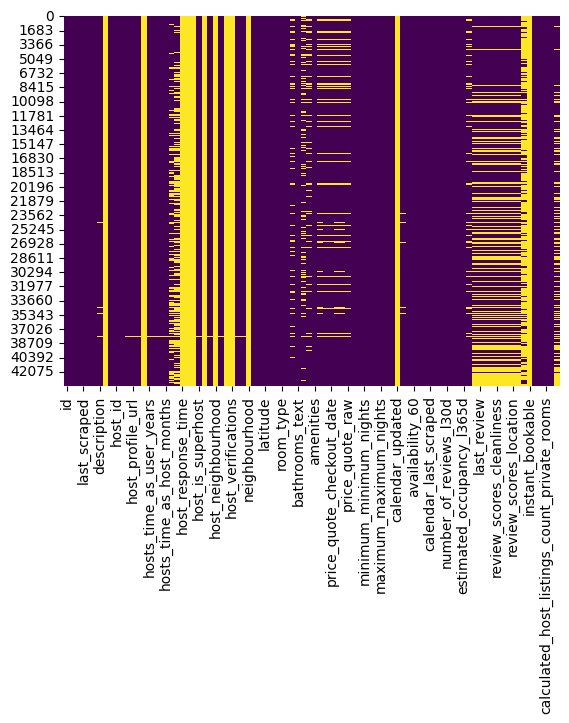

In [48]:
missing_counts = df.isnull().sum()
print("Missing values per column:\n", missing_counts[missing_counts > 0])
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')


### Reflection:
1. What are the top 3 columns with the most missing values?
2. Which ones are likely to create business issues?
3. Which could be safely ignored or dropped?

### ✍️ Your Response: 🔧
1. The top 3 column wiht the most missing values are calendar_updated, license, and nerihborhood_overview.

2. Missing review scores or price data create issues because managers can't calculate average ratings or build accurate pricing models.

3. Calendar_updated and license can be safely dropped because they are almost completely empty and don't add value to the analysis.


## 3. Drop Columns That Aren’t Useful

### Business framing:  

Not every column adds value. Analysts often remove columns that are too empty, irrelevant, or repetitive — especially when preparing data for others.

### Do the following:
Make a decision:

- Choose 2–4 columns to drop from your dataset
- Document your reasons for each one
- Confirm they're gone with `.head()` or `.info()`

In [49]:
cols_to_drop = ['calendar_updated', 'license', 'scrape_id', 'neighborhood_overview']
df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])
df.head(2)

,id,listing_url,last_scraped,source,name,description,picture_url,host_id,host_url,host_profile_id,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2708,https://www.airbnb.com/rooms/2708,2026-06-15,city scrape,"Run Runyon, Beaut Furn Mirror Mini-Suit w/ Fir...",Run Runyon Canyon<br /><br />Gym & Sauna <br /...,https://a0.muscache.com/pictures/hosting/Hosti...,3008,https://www.airbnb.com/users/show/3008,1.462506e+18,...,5.00,4.98,4.96,4.87,NaN,2,0,2,0,0.32
1,2732,https://www.airbnb.com/rooms/2732,2026-06-16,city scrape,Zen Life at the Beach,An oasis of tranquility awaits you.,https://a0.muscache.com/pictures/1082993/c5a99...,3041,https://www.airbnb.com/users/show/3041,1.462506e+18,...,4.39,4.48,4.91,4.22,NaN,2,1,1,0,0.13


### Reflection:
1. Which columns did you drop?
2. Why were they not useful from a business perspective?
3. What could go wrong if you left them in?

### ✍️ Your Response: 🔧
1. calendar_updated, license, scrape_id, and neighborhood_overview

2. scrape_id is just technical background data, calendar_updated and license are almost entirely missing, and neighborhood_overview is just long paragraphs of text.

3. Leaving empty or useless text columns makes the dataset bigger than it needs to be, slows down processing, and clutters up charts.



## 4. Fill or Fix Values in Key Columns

### Business framing:  

Let’s say your manager wants to see a map of listings with prices and review scores. If key fields are blank, the map won’t work. But not all missing values should be filled the same way.

### Do the following:
- Choose 2 columns with missing values
- Use a strategy to fill or flag those values
  - (e.g., median, “unknown”, forward-fill, or a placeholder)
- Explain what you did and why

In [50]:
df['review_scores_communication'] = df['review_scores_communication'].fillna(df['review_scores_communication'].median())
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)
print(df[['review_scores_communication', 'reviews_per_month']].isnull().sum())

review_scores_communication    0
reviews_per_month              0
dtype: int64


### Reflection:
1. What two columns did you clean?
2. What method did you use for each, and why?
3. What risks are there in how you filled the data?

### ✍️ Your Response: 🔧
1. review_scores_communication and reviews_per_month.

2. I filled missing review scores with the median score to keep the overall average fair. For reviews_per_month, I filled missing values with 0 because no reviews simply means 0 per month.

3. Filling missing review scores with the median might make a brand new or bad property look better than it actually is.


## 5. Convert and Clean Data Types

### Business framing:  

Sometimes columns that look like numbers are actually stored as text — which breaks calculations and slows down analysis. Common examples are price columns with dollar signs or availability stored as strings.

### Do the following:
- Identify one column with the wrong data type
- Clean and convert it into a usable format (e.g., from string to number)
- Check your work by summarizing or plotting the cleaned column

In [51]:
df['price'] = df['price'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False)
df['price'] = pd.to_numeric(df['price'], errors='coerce')
print(df['price'].describe())


count    38186.000000
mean       383.395071
std        663.855892
min          3.770000
25%        115.815000
50%        223.670000
75%        405.975000
max      20583.330000
Name: price, dtype: float64


### Reflection: :
1. What column did you fix?
2. What cleaning steps did you apply?
3. How does this help prepare the data for later use?

### ✍️ Your Response: 🔧
1. I fixed the price column.

2. I stripped out the dollar sign ($) and commas, then converted the column from text into a numeric float type.

3. Converting price to numbers lets us calculate average prices, run financial models, and create accurate charts.

## 6. Remove Duplicate Records

### Business framing:  

If a listing appears twice, it could inflate revenue estimates or confuse users. Airbnb needs each listing to be unique and accurate.

### Do the following:
- Check for rows that are exact duplicates
- If your data has an ID column and each ID is supposed to unique, then make sure there are no duplicate IDs
- Remove duplicates if found

In [52]:
print("Duplicate IDs found:", df.duplicated(subset=['id']).sum())
df = df.drop_duplicates(subset=['id'], keep='first')
print("Clean dataset shape:", df.shape)

Duplicate IDs found: 0
Clean dataset shape: (43751, 86)


### Reflection:
1. Did you find duplicates?
2. How did you decide what to drop or keep?
3. Why are duplicates risky for Airbnb teams?

### ✍️ Your Response: 🔧 🔧
1. I checked for duplicate listing IDs to make sure each property was only listed once.

2. I kept the first instance of each listing ID and dropped any extra copies that showed up later.


3. Duplicates artificially inflate total property counts, make local availability look higher than it is, and double-count expected revenue.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 7**, where you'll perform data transformation techniques.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_6.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```





In [53]:
df.to_csv('cleaned_airbnb_data_6.csv', index=False)
print("File exported successfully!")

File exported successfully!


## 8. Final Reflection

You’ve just cleaned a real-world Airbnb dataset — the kind of work that happens every day in analyst and data science roles.

Before you move on to data transformation in Assignment 7, take a few moments to reflect on the decisions you made and what you learned.

### Reflection:
1. Which section of the assignment was the most challenging for you? What made it challenging? Was it the coding or the application of class concepts?
2. Look back at your assignment and discuss a time when you had to drop, fix, or keep a piece of data. Why was it necessary to drop, fix, or keep that specific piece of data? (e.x. dropping a column full of null values because it has no useful information)
3. What’s one way a business team (e.g., hosts, pricing analysts, app administrators) might benefit from the cleaned version of this data?
4. If you had more time, what would you explore or clean further?
5. How does this relate to your customized learning outcome you created in canvas?


Write your response clearly in full sentences. No more than a few sentences required per response.


### ✍️ Your Response: 🔧

1. __  Deciding how to fill missing values in Section 4 was the most challenging part. The coding was straightforward, but deciding whether to use a zero or a median required thinking carefully about the business logic.
2. __ I had to drop the calendar_updated column because it was almost 100% blank. Keeping an empty column serves no purpose and just clutters up the dataset.
3. __  Pricing analysts can immediately calculate market averages and run pricing scripts without errors caused by missing values, text symbols, or duplicate rows.
4. __  I would clean the amenities column by splitting the text lists into simple true/false columns like has_wifi or has_pool.
5. __  This directly connects to my goal of practicing hands-on data cleaning and learning how to prepare raw datasets for real-world reporting and analytics.


## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [54]:
!jupyter nbconvert --to html "assignment_06_data_cleaning.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_06_data_cleaning.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=Tru